# Segmentation-based Bangla word prototype

Reuse the saved ResNet-18; no training or original notebook rerun is needed.
Install dependencies in your existing `.venv` using `requirements-segmentation.txt`.
Predictions are experimental: matra, touching glyphs and vowel signs can fail.


## 1. Local paths


In [1]:
# Choose the same existing Python work/.venv as the kernel.
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, HTML
from html import escape

PROJECT_DIR = Path.cwd().resolve()
CHECKPOINT = PROJECT_DIR / 'training_runs/macos_resnet18_efficientnetb0_v1/character/resnet18/best_model.pt'
LABELS_PATH = PROJECT_DIR / 'labels.json'
REPORT_DIR = PROJECT_DIR / 'reports' / 'segmentation_prototype'

REPORT_DIR.mkdir(parents=True, exist_ok=True)
assert CHECKPOINT.is_file(), f'Update CHECKPOINT: {CHECKPOINT}'
assert LABELS_PATH.is_file(), 'Keep the supplied labels.json next to this notebook.'
print('Python:', sys.executable)
print('Checkpoint:', CHECKPOINT)


Python: /Users/sakibsmacbookm5/Documents/Python work/.venv/bin/python
Checkpoint: /Users/sakibsmacbookm5/Documents/Python work/research-project/SICIP - Assignment 4/training_runs/macos_resnet18_efficientnetb0_v1/character/resnet18/best_model.pt


## 2. Character model and segmentation helpers

These are ordinary Python definitions, also available in `segmentation_ocr.py`.
The model preprocessing matches training. Only geometry rules propose **া** and **ু**;
these are not trained modifier predictions. No dictionary supplies the answer.


In [2]:
import json
import math
import time
import unicodedata
from pathlib import Path
import cv2
import numpy as np
import torch
import torch.nn as nn
import torchvision
from PIL import Image, ImageOps
from torchvision.transforms import functional as TF


In [3]:
DEFAULT_SETTINGS = {
    "max_width": 1400,
    "max_segments": 24,
    "min_confidence": 0.30,
    "headline_min_coverage": 0.55,
    "modifier_rules": True,
    "top_k": 3,
}


In [4]:
class ResNetCharacterModel(nn.Module):
    def __init__(self):
        super().__init__()

        network = torchvision.models.resnet18(weights=None)
        self.encoder = nn.Sequential(*list(network.children())[:-2])
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Dropout(0.25), nn.Linear(512, 84),
        )

    def forward(self, images):
        return self.head(self.encoder(images))


In [5]:
def load_engine(checkpoint, labels_path="labels.json", device="cpu", settings=None):
    # These are the user's own inference weights; load only tensor-safe objects.
    saved = torch.load(checkpoint, map_location="cpu", weights_only=True)

    if saved.get("architecture") != "resnet18" or saved.get("task") != "character":
        raise ValueError("Expected the saved ResNet-18 character checkpoint.")

    labels = json.loads(Path(labels_path).read_text(encoding="utf-8"))
    if set(labels) != {str(i) for i in range(1, 85)}:
        raise ValueError("labels.json must contain the original class IDs 1..84.")

    model = ResNetCharacterModel()
    model.load_state_dict(saved["state_dict"], strict=True)
    model.to(device).eval()

    return {
        "model": model, "labels": labels, "device": torch.device(device),
        "height": int(saved["height"]), "width": int(saved["width"]),
        "settings": {**DEFAULT_SETTINGS, **(settings or {})},
        "checkpoint": str(checkpoint), "metadata": {k: v for k, v in saved.items() if k != "state_dict"},
    }


In [6]:
def foreground_gray(image):
    if isinstance(image, (str, Path)):
        with Image.open(image) as opened:
            image = opened.copy()
    elif isinstance(image, np.ndarray):
        image = Image.fromarray(image.astype(np.uint8))

    if image.mode in ("RGBA", "LA") or "transparency" in image.info:
        rgba = image.convert("RGBA")
        image = Image.alpha_composite(Image.new("RGBA", rgba.size, "white"), rgba)

    pixels = np.array(ImageOps.exif_transpose(image).convert("L"), dtype=np.uint8)
    border = np.concatenate([pixels[0], pixels[-1], pixels[:, 0], pixels[:, -1]])

    if np.median(border) > 127:
        pixels = 255 - pixels

    if int(pixels.max()) - int(pixels.min()) < 16:
        raise ValueError("Blank or almost constant image.")

    return pixels


In [7]:
def character_tensor(pixels, height=128, width=128):
    # Match normalise_ink(), image_canvas() and canvas_tensor() from training.
    y, x = np.where(pixels > 32)
    if not len(x):
        raise ValueError("Empty character crop.")

    image = Image.fromarray(pixels[y.min():y.max() + 1, x.min():x.max() + 1])
    scale = min((height - 8) / image.height, (width - 8) / image.width)
    size = (max(1, round(image.width * scale)), max(1, round(image.height * scale)))
    image = image.resize(size, Image.Resampling.BILINEAR)

    canvas = Image.new("L", (width, height), 0)
    canvas.paste(image, ((width - image.width) // 2, (height - image.height) // 2))
    tensor = TF.to_tensor(canvas).expand(3, -1, -1)

    return TF.normalize(tensor, [0.485, 0.456, 0.406], [0.229, 0.224, 0.225])


In [8]:
def prepare_word(image, settings):
    gray = foreground_gray(image)
    y, x = np.where(gray > 32)
    if not len(x):
        raise ValueError("No visible writing.")

    gray = gray[y.min():y.max() + 1, x.min():x.max() + 1]
    if gray.shape[1] > settings["max_width"]:
        scale = settings["max_width"] / gray.shape[1]
        gray = cv2.resize(gray, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)

    _, mask = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    return gray, mask


In [9]:
def find_headline(mask, minimum_coverage):
    height, width = mask.shape
    if width < 20 or height < 12:
        return None

    # A strong horizontal run in the upper portion is a candidate matra.
    kernel_width = max(5, min(width // 3, int(height * 0.6)))
    horizontal = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((1, kernel_width), np.uint8))
    counts = np.count_nonzero(horizontal, axis=1)
    end = max(2, int(height * 0.65))
    row = int(np.argmax(counts[:end]))

    if counts[row] / width < minimum_coverage:
        return None

    top = bottom = row
    while top > 0 and counts[top - 1] >= counts[row] * 0.65:
        top -= 1
    while bottom + 1 < end and counts[bottom + 1] >= counts[row] * 0.65:
        bottom += 1

    return top, bottom + 1


In [10]:
def component_boxes(mask):
    count, _, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    minimum_area = max(2, round(mask.size * 0.00012))
    boxes = []

    for x, y, width, height, area in stats[1:count]:
        if area >= minimum_area:
            boxes.append([int(x), int(y), int(x + width), int(y + height)])

    return sorted(boxes)


In [11]:
def union_box(left, right):
    return [min(left[0], right[0]), min(left[1], right[1]),
            max(left[2], right[2]), max(left[3], right[3])]


In [12]:
def group_vertical_parts(boxes):
    # Keep a detached dot and the body beneath it in one candidate crop.
    groups = []

    for box in sorted(boxes):
        matches = []
        for index, group in enumerate(groups):
            overlap = min(box[2], group[2]) - max(box[0], group[0])
            small_width = min(box[2] - box[0], group[2] - group[0])
            if overlap > max(0, small_width * 0.25):
                matches.append(index)

        for index in reversed(matches):
            box = union_box(box, groups.pop(index))
        groups.append(box)

    return sorted(groups)


In [13]:
def boxes_for_intervals(mask, intervals):
    boxes = []
    for left, right in intervals:
        y, x = np.where(mask[:, left:right] > 0)
        if len(x):
            boxes.append([left + int(x.min()), int(y.min()),
                          left + int(x.max()) + 1, int(y.max()) + 1])

    return boxes


In [14]:
def projection_intervals(mask):
    occupied = np.count_nonzero(mask, axis=0) > 0
    transitions = np.diff(np.pad(occupied.astype(int), (1, 1)))
    starts = np.where(transitions == 1)[0]
    ends = np.where(transitions == -1)[0]

    return list(zip(starts.tolist(), ends.tolist()))


In [15]:
def split_wide_boxes(mask, boxes):
    # Offer a second hypothesis for touching glyphs instead of always forcing a cut.
    output = []
    for box in boxes:
        left, top, right, bottom = box
        height, width = bottom - top, right - left
        if width < height * 1.35:
            output.append(box)
            continue

        projection = np.count_nonzero(mask[top:bottom, left:right], axis=0)
        low, high = max(1, int(width * 0.30)), min(width - 1, int(width * 0.70))
        if high <= low:
            output.append(box)
            continue
        cut = low + int(np.argmin(projection[low:high]))

        if projection[cut] <= max(2, projection.max() * 0.35):
            output.extend(boxes_for_intervals(mask, [(left, left + cut), (left + cut, right)]))
        else:
            output.append(box)

    return output


In [16]:
def restore_crop_extent(mask, boxes):
    # Segmentation may erase the matra, but inference retains original strokes.
    intervals = [(box[0], box[2]) for box in boxes]

    return boxes_for_intervals(mask, intervals)


In [17]:
def segmentation_candidates(mask, settings):
    candidates = [("components", group_vertical_parts(component_boxes(mask)))]
    headline = find_headline(mask, settings["headline_min_coverage"])
    body = mask.copy()

    if headline is not None:
        body[headline[0]:headline[1]] = 0
        grouped = group_vertical_parts(component_boxes(body))
        candidates.append(("matra-components", restore_crop_extent(mask, grouped)))

    projection = boxes_for_intervals(body, projection_intervals(body))
    candidates.append(("vertical-projection", restore_crop_extent(mask, projection)))
    candidates.append(("touching-valley", restore_crop_extent(mask, split_wide_boxes(body, projection))))

    # Disconnected pieces can belong to one letter, as in an independently written আ.
    if len(candidates[0][1]) <= 8:
        components = candidates[0][1]
        for index in range(len(components) - 1):
            joined = union_box(components[index], components[index + 1])
            if joined[2] - joined[0] < (joined[3] - joined[1]) * 1.45:
                boxes = components[:index] + [joined] + components[index + 2:]
                candidates.append((f"merge-parts-{index + 1}", boxes))

    result, seen = [], set()
    for name, boxes in candidates:
        key = tuple(tuple(box) for box in boxes)
        if key and key not in seen and len(boxes) <= settings["max_segments"]:
            result.append((name, boxes))
            seen.add(key)

    return result, headline, body


In [18]:
def crop_options(gray, boxes, settings):
    options = []
    baseline = float(np.median([box[3] for box in boxes]))
    median_height = float(np.median([box[3] - box[1] for box in boxes]))

    for index, box in enumerate(boxes):
        left, top, right, bottom = box
        crop = gray[top:bottom, left:right]
        options.append({"segment": index, "pixels": crop, "modifier": "", "rule": "classifier"})

        # A descending, narrow extra region can be a short-u sign; this remains heuristic.
        extra = bottom - baseline
        if settings["modifier_rules"] and len(boxes) > 1 and extra > median_height * 0.12:
            cut = int(round(baseline - top))
            lower = crop[cut:]
            if cut > crop.shape[0] * 0.55 and lower.size and np.count_nonzero(lower > 32) > 3:
                y, x = np.where(lower > 32)
                if len(x) and x.max() - x.min() + 1 < crop.shape[1] * 0.85:
                    options.append({"segment": index, "pixels": crop[:cut],
                                    "modifier": "ু", "rule": "lower-zone short-u hypothesis"})

    return options


In [19]:
@torch.inference_mode()
def classify_options(engine, options):
    tensors = [character_tensor(o["pixels"], engine["height"], engine["width"]) for o in options]
    probabilities = []

    for start in range(0, len(tensors), 32):
        batch = torch.stack(tensors[start:start + 32]).to(engine["device"])
        probabilities.extend(engine["model"](batch).softmax(-1).cpu().numpy())

    for option, scores in zip(options, probabilities):
        indices = np.argsort(scores)[-engine["settings"]["top_k"]:][::-1]
        option["top_k"] = [{"class_id": int(i) + 1, "text": engine["labels"][str(int(i) + 1)],
                            "probability": float(scores[i])} for i in indices]
        option["confidence"] = option["top_k"][0]["probability"]
        option["text"] = option["top_k"][0]["text"]
        option["class_id"] = option["top_k"][0]["class_id"]

    return options


In [20]:
def is_aa_stroke(gray, box, median_height):
    left, top, right, bottom = box
    width, height = right - left, bottom - top
    if height < median_height * 0.65 or width / max(height, 1) > 0.65:
        return False

    foreground = gray[top:bottom, left:right] > 32
    middle = foreground[int(height * 0.25):max(1, int(height * 0.90))]
    spans = []
    for row in middle:
        x = np.flatnonzero(row)
        if len(x):
            spans.append(int(x[-1] - x[0] + 1))

    return (bool(spans) and len(spans) >= len(middle) * 0.75 and
            np.median(spans) <= height * 0.22 and
            np.count_nonzero(foreground, axis=0).max() >= height * 0.60)


In [21]:
def choose_tokens(gray, boxes, options, settings):
    tokens = []
    median_height = float(np.median([b[3] - b[1] for b in boxes]))

    for index, box in enumerate(boxes):
        candidates = [o for o in options if o["segment"] == index]
        # A modifier hypothesis needs a clear classifier improvement over the full crop.
        best = max(candidates, key=lambda o: math.log(max(o["confidence"], 1e-8)) - 0.30 * bool(o["modifier"]))
        token = {k: v for k, v in best.items() if k != "pixels"}
        token["box"] = list(box)

        if settings["modifier_rules"] and tokens and is_aa_stroke(gray, box, median_height):
            if not tokens[-1]["text"].isdigit():
                token.update(text="া", class_id=None, modifier="",
                             rule="right vertical aa-sign hypothesis", confidence=0.55)

        if token["confidence"] < settings["min_confidence"]:
            token["text"] = "�"
        tokens.append(token)

    return tokens


In [22]:
def score_tokens(tokens):
    score = 0.0
    for token in tokens:
        left, top, right, bottom = token["box"]
        ratio = (right - left) / max(1, bottom - top)
        score += math.log(max(token["confidence"], 1e-8))
        score -= max(0.0, ratio - 1.3) * 0.7
        score -= 0.6 * (token["text"] == "�")

    return score / max(len(tokens), 1)


In [23]:
def assemble_word(tokens):
    # Unicode shaping joins the output; no expected answer or dictionary is supplied.
    text = "".join(token["text"] + token["modifier"] for token in tokens)

    return unicodedata.normalize("NFC", text.replace("অা", "আ"))


In [24]:
def prediction_warnings(tokens, headline):
    warnings = []
    if any(token["rule"] != "classifier" for token in tokens):
        warnings.append("Vowel-sign geometry rules were used; inspect the segmentation preview.")
    if any(token["text"] == "�" for token in tokens):
        warnings.append("At least one segment has low classifier confidence.")
    if headline is not None:
        warnings.append("A matra-removal hypothesis was considered; touching characters may remain ambiguous.")

    warnings.append("This prototype has no trained dependent-vowel or word model; other modifiers/conjuncts may fail.")

    return warnings


In [25]:
def predict_word(engine, image):
    started = time.perf_counter()
    gray, mask = prepare_word(image, engine["settings"])
    candidates, headline, body = segmentation_candidates(mask, engine["settings"])
    alternatives = []

    for method, boxes in candidates:
        options = crop_options(gray, boxes, engine["settings"])
        options = classify_options(engine, options)
        tokens = choose_tokens(gray, boxes, options, engine["settings"])
        alternatives.append({"method": method, "word": assemble_word(tokens),
                             "score": score_tokens(tokens), "tokens": tokens})

    if not alternatives:
        raise ValueError("No usable character segmentation. Try clearer writing or increase spacing.")

    alternatives.sort(key=lambda item: item["score"], reverse=True)
    best = alternatives[0]
    confidence = math.exp(sum(math.log(max(t["confidence"], 1e-8)) for t in best["tokens"]) / len(best["tokens"]))

    return {
        "word": best["word"], "method": best["method"], "tokens": best["tokens"],
        "confidence": confidence, "confidence_is_calibrated": False,
        "alternatives": alternatives, "warnings": prediction_warnings(best["tokens"], headline),
        "latency_ms": (time.perf_counter() - started) * 1000,
        "debug": {"gray": gray, "mask": mask, "body_mask": body, "headline": headline},
    }


## 3. Load your saved weights


In [26]:
# CPU inference is enough for this small prototype. No weights are downloaded.
engine = load_engine(CHECKPOINT, LABELS_PATH, device='cpu')

print('Architecture:', engine['metadata']['architecture'])
print('Best character epoch:', engine['metadata']['best_epoch'])
print('Labels:', len(engine['labels']))
print('Training mode:', engine['model'].training)  # Must be False.
print('Settings:', engine['settings'])


Architecture: resnet18
Best character epoch: 29
Labels: 84
Training mode: False
Settings: {'max_width': 1400, 'max_segments': 24, 'min_confidence': 0.3, 'headline_min_coverage': 0.55, 'modifier_rules': True, 'top_k': 3}


## 4. Visual label audit

The map uses BanglaLekha's one-based IDs, not PromitoLipi's IDs.
Sources are recorded in `label_sources.json`. Review the glyphs below if changing labels.


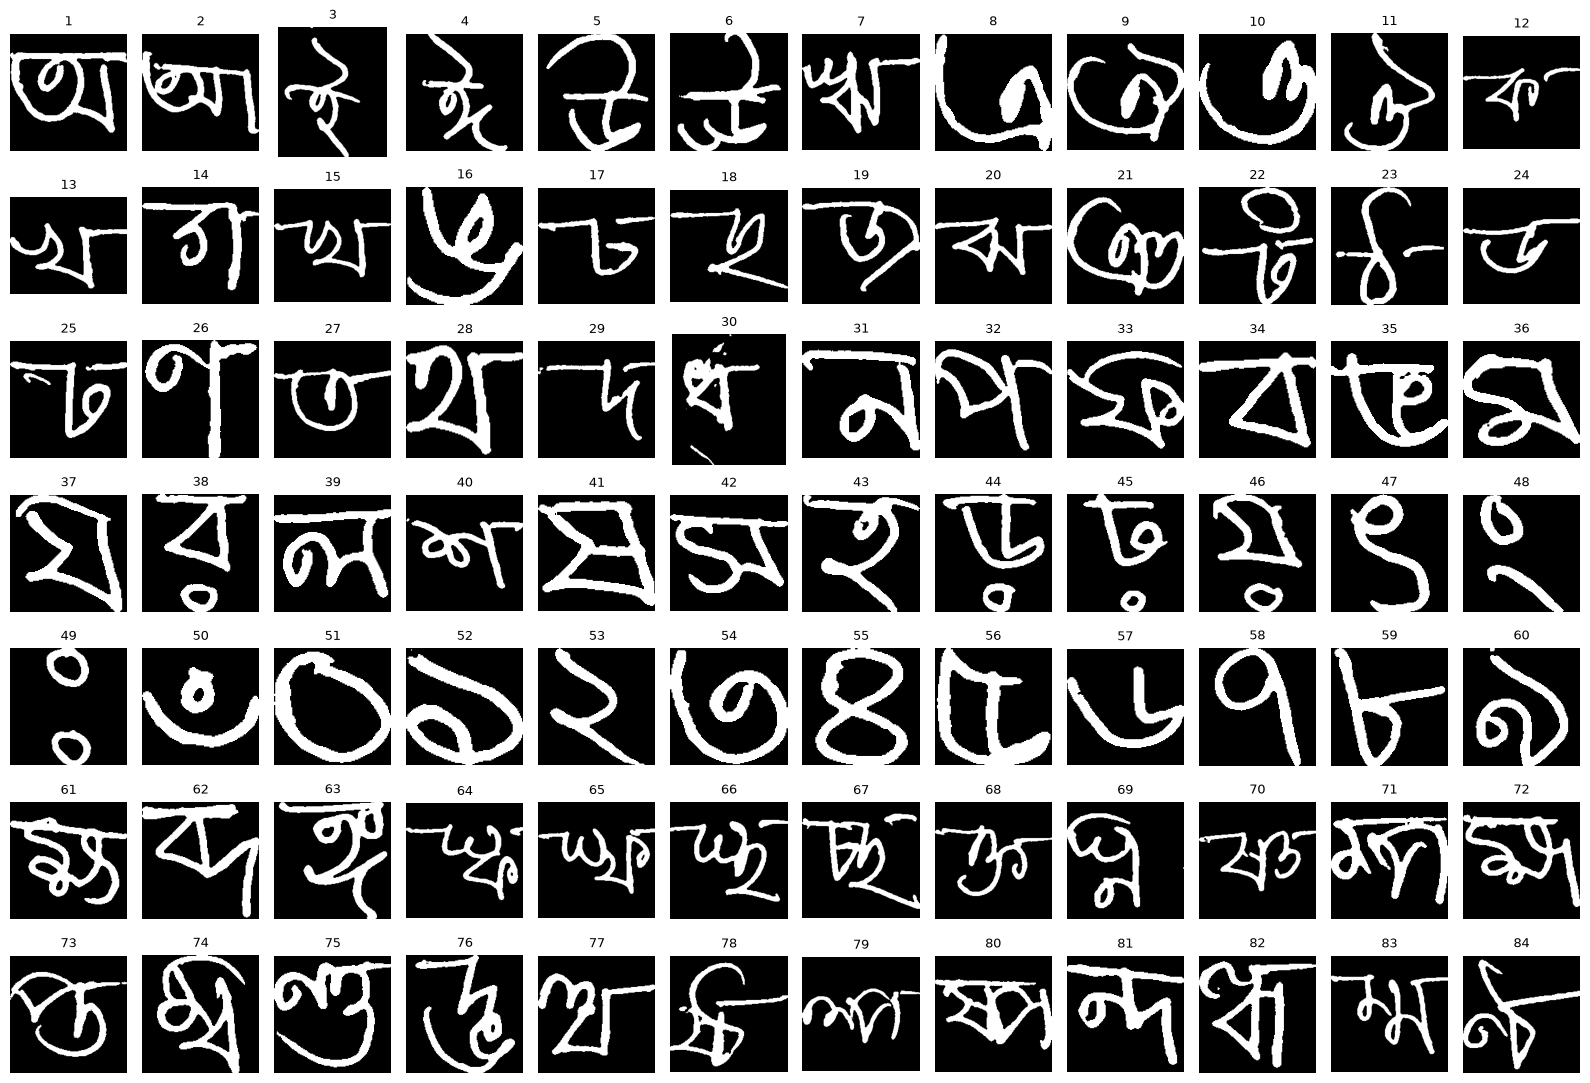

,class_id,Bangla
0,1,অ
1,2,আ
2,3,ই
3,4,ঈ
4,5,উ
...,...,...
79,80,ষ্প
80,81,ন্দ
81,82,ন্ধ
82,83,ম্ম


In [27]:
# This optional gallery needs local character images, not the old training cache.
image_root = PROJECT_DIR / 'BanglaLekha-Isolated' / 'Images'

if image_root.is_dir():
    fig, axes = plt.subplots(7, 12, figsize=(16, 11))

    for class_id, ax in zip(range(1, 85), axes.flat):
        path = sorted((image_root / str(class_id)).glob('*.png'))[10]
        with Image.open(path) as image:
            ax.imshow(image.convert('L'), cmap='gray')
        ax.set_title(str(class_id), fontsize=9)
        ax.axis('off')

    fig.tight_layout()
    fig.savefig(REPORT_DIR / 'label_audit.png', dpi=150)
    plt.show()
    plt.close(fig)

display(pd.DataFrame([
    {'class_id': int(key), 'Bangla': value} for key, value in engine['labels'].items()
]))


## 5. Display the joined word and segmentation diagnostics


In [28]:
def show_result(result):
    # Display the COMPLETE word first. Segment labels are diagnostics underneath.
    display(HTML('<h3>Predicted whole word: ' + escape(result['word']) + '</h3>'))
    print('Method:', result['method'], '| time:', round(result['latency_ms'], 1), 'ms')
    print('Classifier score:', round(result['confidence'], 3), '(uncalibrated; not word accuracy)')

    debug = result['debug']
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    axes[0].imshow(debug['gray'], cmap='gray')
    axes[0].set_title('Input: white ink on black')
    axes[1].imshow(debug['body_mask'], cmap='gray')
    axes[1].set_title('Segmentation mask')
    axes[2].imshow(debug['gray'], cmap='gray')
    axes[2].set_title('Selected character boxes')

    for index, token in enumerate(result['tokens'], 1):
        left, top, right, bottom = token['box']
        box = plt.Rectangle((left, top), right - left, bottom - top, fill=False, color='red')
        axes[2].add_patch(box)
        axes[2].text(left, max(0, top - 2), str(index), color='red')

    for ax in axes:
        ax.axis('off')
    fig.tight_layout()
    plt.show()
    return fig


In [29]:
def result_tables(result):
    rows = [{
        'segment': token['segment'] + 1,
        'class_id': token['class_id'],
        'character': token['text'],
        'added_sign': token['modifier'],
        'score': round(token['confidence'], 3),
        'rule': token['rule'],
    } for token in result['tokens']]

    display(pd.DataFrame(rows))
    display(pd.DataFrame([
        {key: item[key] for key in ['method', 'word', 'score']}
        for item in result['alternatives']
    ]))

    for warning in result['warnings']:
        print('Note:', warning)


In [30]:
def save_result(result, name):
    # Keep machine-readable predictions separately from NumPy visualization arrays.
    record = {key: value for key, value in result.items() if key != 'debug'}
    (REPORT_DIR / f'{name}.json').write_text(
        json.dumps(record, ensure_ascii=False, indent=2), encoding='utf-8',
    )


def inspect_word(path, name='custom_word'):
    result = predict_word(engine, path)
    figure = show_result(result)
    figure.savefig(REPORT_DIR / f'{name}.png', dpi=160, bbox_inches='tight')
    plt.close(figure)

    result_tables(result)
    save_result(result, name)

    return result


## 6. Try real word images

These fixed PromitoLipi examples illustrate both successes and failures; they are not
a representative benchmark. Their XML files contain component IDs, not word transcripts.
No XML annotation is read by the predictor.


Image: 1128.bmp


Method: vertical-projection | time: 66.1 ms
Classifier score: 0.944 (uncalibrated; not word accuracy)


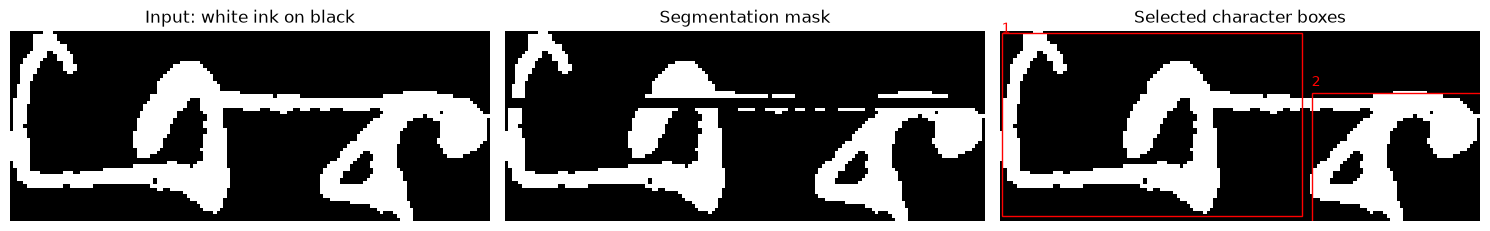

,segment,class_id,character,added_sign,score,rule
0,1,8,এ,,0.922,classifier
1,2,12,ক,,0.967,classifier


,method,word,score
0,vertical-projection,এক,-0.177703
1,matra-components,এব্দরক,-0.334731
2,touching-valley,�এক,-1.031529
3,components,�,-3.206604


Note: A matra-removal hypothesis was considered; touching characters may remain ambiguous.
Note: This prototype has no trained dependent-vowel or word model; other modifiers/conjuncts may fail.
Image: 0.bmp


Method: components | time: 40.1 ms
Classifier score: 0.38 (uncalibrated; not word accuracy)


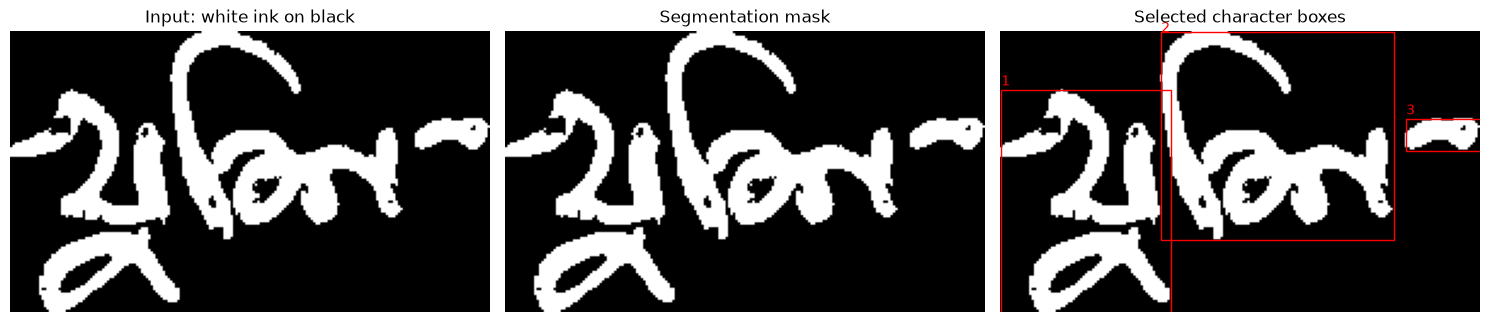

,segment,class_id,character,added_sign,score,rule
0,1,69,স্ন,,0.694,classifier
1,2,40,শ,,0.854,classifier
2,3,60,�,,0.092,classifier


,method,word,score
0,components,স্নশ�,-1.421882
1,touching-valley,স্নশ�,-1.525246
2,vertical-projection,ষ্পু�,-2.253710


Note: At least one segment has low classifier confidence.
Note: This prototype has no trained dependent-vowel or word model; other modifiers/conjuncts may fail.
Image: 10911.bmp


Method: matra-components | time: 28.3 ms
Classifier score: 0.727 (uncalibrated; not word accuracy)


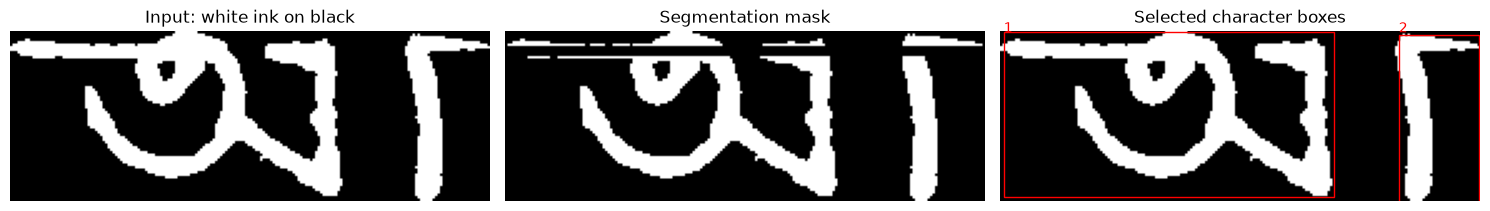

,segment,class_id,character,added_sign,score,rule
0,1,1.0,অ,,0.96,classifier
1,2,NaN,া,,0.55,right vertical aa-sign hypothesis


,method,word,score
0,matra-components,আ,-0.564363
1,components,আ,-0.569763
2,touching-valley,�আ,-1.020529


Note: Vowel-sign geometry rules were used; inspect the segmentation preview.
Note: A matra-removal hypothesis was considered; touching characters may remain ambiguous.
Note: This prototype has no trained dependent-vowel or word model; other modifiers/conjuncts may fail.


,image,prediction
0,1128.bmp,এক
1,0.bmp,স্নশ�
2,10911.bmp,আ


In [31]:
promito = (
    PROJECT_DIR / 'Handwritten word' /
    'PromitoLipi A versatile offline dataset of handwritten Bangla words and paragraphs' /
    'PromitoLipi' / 'PromitoLipi2.1' / 'Word Images(bmp)'
)

example_results = []

for name in ['1128', '0', '10911']:
    path = promito / f'{name}.bmp'
    if path.is_file():
        print('Image:', path.name)
        result = inspect_word(path, f'promito_{name}')
        example_results.append({'image': path.name, 'prediction': result['word']})

if example_results:
    display(pd.DataFrame(example_results))
else:
    print('Optional PromitoLipi examples were not found; use your own image in the next cell.')


In [32]:
# Point this at a new drawing of জল, মানুষ, or another word. No expected word is supplied.
IMAGE_PATH = None  # Example: PROJECT_DIR / 'my_word.png'

if IMAGE_PATH is not None:
    custom_result = inspect_word(IMAGE_PATH)


## 7. Controlled software check

This constructs **জল** from two isolated handwritten characters with a gap.
It checks segmentation, classification and joining; success does not measure natural-word accuracy.


In [33]:
def isolated_character_canvas(image_root, class_ids):
    pieces = []

    for class_id in class_ids:
        path = sorted((image_root / str(class_id)).glob('*.png'))[10]
        with Image.open(path) as image:
            pixels = foreground_gray(image)
        y, x = np.where(pixels > 32)
        image = Image.fromarray(pixels[y.min():y.max() + 1, x.min():x.max() + 1])
        image.thumbnail((100, 100))
        pieces.append(image)

    canvas = Image.new('L', (sum(image.width for image in pieces) + 50, 125), 0)
    left = 15

    for image in pieces:
        canvas.paste(image, (left, 10))
        left += image.width + 20

    return canvas


Method: components | time: 26.3 ms
Classifier score: 0.953 (uncalibrated; not word accuracy)


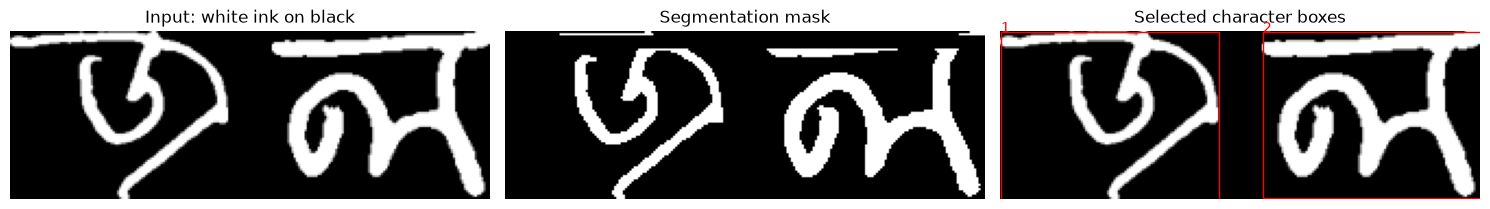

Software-check reference: জল
Actual prediction: জল


In [34]:
if image_root.is_dir():
    diagnostic_image = isolated_character_canvas(image_root, [19, 39])
    diagnostic_image.save(REPORT_DIR / 'synthetic_jol_input.png')

    diagnostic = predict_word(engine, diagnostic_image)
    figure = show_result(diagnostic)
    plt.close(figure)

    print('Software-check reference: জল')
    print('Actual prediction:', diagnostic['word'])
    save_result(diagnostic, 'synthetic_jol_result')


## 8. Test your own labeled drawings

For a real word-accuracy measurement, provide a CSV with `path,expected` and independent
drawings. Use the same settings for every test; report all results, including failures.


In [35]:
# Paths in this optional CSV are relative to the CSV's folder.
# Example CSV row: images/my_drawing.png,মানুষ
TEST_CSV = None

if TEST_CSV is not None:
    test_csv = Path(TEST_CSV)
    tests = pd.read_csv(test_csv, dtype=str, keep_default_na=False)
    assert {'path', 'expected'}.issubset(tests.columns)
    assert len(tests) > 0 and tests['expected'].str.strip().ne('').all()
    records = []

    for row in tests.itertuples():
        try:
            result = predict_word(engine, test_csv.parent / row.path)
            prediction, error = result['word'], ''
        except (OSError, ValueError) as problem:
            prediction, error = '', str(problem)

        expected = unicodedata.normalize('NFC', row.expected.strip())
        records.append({'path': row.path, 'expected': expected, 'prediction': prediction,
                        'correct': prediction == expected, 'error': error})

    evaluation = pd.DataFrame(records)
    evaluation.to_csv(REPORT_DIR / 'word_evaluation.csv', index=False)
    display(evaluation)
    print('Exact word accuracy:', evaluation['correct'].mean())
else:
    print('No natural-handwriting word accuracy is claimed without labeled test drawings.')


No natural-handwriting word accuracy is claimed without labeled test drawings.
